In [ ]:
import sys
import zipfile
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from xgboost import XGBClassifier

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))

import config as C
from src import save_plot

In [ ]:
COELHO = C.DATA / "source" / "coelho2024"
SUPPLEMENT = COELHO / "41588_2024_1948_MOESM4_ESM.xlsx"
COUNTS_ZIP = COELHO / "logcounts_ABE.zip"
FACTOR_COUNTS = [5, 10, 15, 20, 25]
DRAWS = 10          
SEEDS = 3           
FOLDS = 5
HIGH_VARIANCE_GENES = 2000
RESISTANCE, CONTROL = "Resistance", "Control"

# Predicting drug resistance from single-cell transcriptomes


In [3]:
meta = pd.read_csv(COELHO / "meta_ABE.csv", index_col=0, low_memory=False)
meta.variant_class_highest_impact.value_counts().rename("cells").to_frame()

,cells
variant_class_highest_impact,
control,8534
drug addiction,590
canonical drug resistance,381


In [4]:
def guides_of(cell_name):
    """The guide identifiers in a cell name, dropping the iBAR parts."""
    return [part for part in str(cell_name).split("-") if not part.startswith("iBAR_")]

In [5]:
meta["guide_list"] = [guides_of(name) for name in meta.index]
meta["n_guides"] = meta.guide_list.str.len()
meta["labels_in_cell"] = [len(set(str(v).split("-"))) for v in meta.variant_class]

In [ ]:
meta["class_list"] = [str(v).split("-") for v in meta.variant_class]
assert (meta.class_list.str.len() == meta.n_guides).all(), "class list does not align"


def attributed_guide(parts, classes):
    if len(parts) == 1:
        return parts[0]
    if len(parts) == 2:
        variant = [part for part, name in zip(parts, classes) if name != "control"]
        if len(variant) == 1:
            return variant[0]
    return None

In [ ]:
meta["attributed"] = [
    attributed_guide(parts, classes)
    for parts, classes in zip(meta.guide_list, meta.class_list)
]
usable = meta[meta.attributed.notna()].copy()
usable["label"] = np.where(
    usable.variant_class_highest_impact.eq("control"), CONTROL, RESISTANCE
)
single = usable.n_guides == 1
assert (usable.loc[single, "attributed"] == usable.loc[single, "gRNA"]).all()

In [41]:
pd.DataFrame(
    {"cells": [
        len(meta),
        int((meta.n_guides == 1).sum()),
        int(((meta.n_guides == 2) & meta.attributed.notna()).sum()),
        -int(meta.attributed.isna().sum()),
        len(usable),
        int(usable.label.eq(RESISTANCE).sum()),
    ]},
    index=["published", "one guide", "two guides, one a control",
           "unattributable, dropped", "usable", "of which resistance"],
)

,cells
published,9505
one guide,7251
"two guides, one a control",251
"unattributable, dropped",-2003
usable,7502
of which resistance,846


In [42]:
per_label = usable.groupby("attributed").label.first().value_counts()
print(f"{usable.attributed.nunique()} variants over {len(usable):,} cells: "
      f"{per_label[RESISTANCE]} resistance, {per_label[CONTROL]} control")
usable.groupby("variant_class_highest_impact").agg(
    cells=("attributed", "size"), variants=("attributed", "nunique")
)

216 variants over 7,502 cells: 20 resistance, 196 control


,cells,variants
variant_class_highest_impact,,
canonical drug resistance,335,8
control,6656,196
drug addiction,511,12


## Linking guides to the variant annotations


In [10]:
st6 = pd.read_excel(SUPPLEMENT, sheet_name="ST6 perturb-seq")
st6["short"] = st6.sgRNA_ID.astype(str).str[:6]
assert st6.short.is_unique, "the six character prefix is not unique in ST6"
short_to_sequence = st6.set_index("short").sequence.astype(str).str.upper()

In [11]:
library = pd.read_csv(C.dataset_file(C.COELHO_STUDY, "library"))
library["upper"] = library.guide.astype(str).str.upper()
by_suffix = {}
for guide in library.upper:
    by_suffix.setdefault(guide[1:], []).append(guide)

In [12]:
records = []
for identifier in usable.gRNA.unique():
    for part in guides_of(identifier):
        gene, _, short = part.rpartition("_")
        sequence = short_to_sequence.get(short)
        candidates = by_suffix.get(sequence, []) if isinstance(sequence, str) else []
        records.append({
            "part": part,
            "gene_label": gene,
            "candidates": len(candidates),
            "guide": candidates[0] if len(candidates) == 1 else None,
        })
link = pd.DataFrame(records).drop_duplicates("part")

In [13]:
annotation = pd.read_csv(C.dataset_file(C.COELHO_STUDY, "annotation"), low_memory=False)
annotation = annotation[annotation.editor == "ABE"]
reached = link.dropna(subset=["guide"]).merge(
    annotation.drop_duplicates("guide")[["guide", "gene"]], on="guide", how="left"
)
agree = reached.dropna(subset=["gene"])
print(f"{len(link)} identifiers, {int(link.candidates.eq(1).sum())} resolved, "
      f"{int(reached.gene.notna().sum())} annotated, gene label agrees "
      f"{(agree.gene_label == agree.gene).mean():.0%}")

216 identifiers, 216 resolved, 133 annotated, gene label agrees 100%


In [43]:
guide_of_part = link.dropna(subset=["guide"]).set_index("part").guide
relevant = annotation[annotation.guide.isin(set(guide_of_part))]
relevant.codon_mutation_category.value_counts().rename("edits").to_frame()

,edits
codon_mutation_category,
Missense,138
Silent,17
Intron,4
Splice-acceptor,1


In [44]:
inventory = pd.read_csv(C.DATA / "features_annotation_inventory.csv", index_col=0)
kept = list(inventory.index[inventory.status == "kept"])

VEP_FEATURES = [
    name if name in relevant.columns else f"vep_{name}"
    for name in kept
    if name in relevant.columns or f"vep_{name}" in relevant.columns
]
assert len(VEP_FEATURES) == len(kept), "some of notebook 03's features are missing here"
numeric = relevant[VEP_FEATURES].apply(pd.to_numeric, errors="coerce")
coverage = numeric.notna().mean()

print(f"{len(VEP_FEATURES)} features from notebook 03, coverage "
      f"{coverage.min():.0%} to {coverage.max():.0%}, "
      f"{len(relevant) / relevant.guide.nunique():.2f} edits per guide")

114 features from notebook 03, coverage 17% to 85%, 1.77 edits per guide


In [ ]:
per_guide = (
    relevant.assign(**{c: numeric[c] for c in VEP_FEATURES})
    .groupby("guide")[VEP_FEATURES]
    .mean()
)
per_guide.head()

,vep_GERP++_NR,vep_GERP++_RS,vep_GERP++_RS_rankscore,vep_phastCons100way_vertebrate,vep_phastCons100way_vertebrate_rankscore,vep_phastCons17way_primate,vep_phastCons17way_primate_rankscore,vep_phyloP100way_vertebrate,vep_phyloP100way_vertebrate_rankscore,vep_phyloP17way_primate,...,vep_MutationTaster_trees_benign,vep_MutationTaster_trees_deleterious,vep_MPC_rankscore,vep_MPC_score,vep_popEVE_converted_rankscore,vep_popEVE_score,spliceai_ds_ag,spliceai_ds_al,spliceai_ds_dg,spliceai_ds_dl
guide,,,,,,,,,,,,,,,,,,,,,
AAAATTCACCGCAGTGCATC,5.82,5.24,0.7663,1.0,0.73103,1.0,0.97333,8.017,0.89427,0.665,...,25.5,74.5,0.906695,1.741551,0.739985,-3.7715,0.050,0.0,0.0,0.00
AACAGGCACCAGAAGTCATC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.335,0.5,0.0,0.00
AAGGAGGCCCAAAAGCGACA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000,0.0,0.0,0.00
ACAAAATAAATCACAAAAAA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ACAAGCCACTCACCAGGCAC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000,0.0,0.0,0.01


In [45]:
aa_parts = annotation.vep_Amino_acids.astype(str).str.split("/")
residue = (
    pd.to_numeric(annotation.vep_Protein_position.astype(str).str.split("-").str[0],
                  errors="coerce")
    .astype("Int64").astype(str)
)
detail = (
    annotation.assign(
        substitution=np.where(
            annotation.vep_Amino_acids.notna(),
            aa_parts.str[0] + residue + aa_parts.str[-1],
            None,
        )
    )
    .groupby("guide")
    .agg(
        gene=("gene", "first"),
        substitution=("substitution", lambda s: "|".join(dict.fromkeys(s.dropna()))),
        consequence=("vep_Consequence", lambda s: "|".join(dict.fromkeys(s.dropna()))),
        edits=("guide", "size"),
    )
)
called = usable[usable.variant_class_highest_impact != "control"]
listing = (
    called.groupby(["variant_class_highest_impact", "attributed"])
    .size().rename("cells").reset_index()
    .rename(columns={"variant_class_highest_impact": "class", "attributed": "guide_id"})
)
listing["guide"] = listing.guide_id.map(guide_of_part)
listing = listing.join(detail, on="guide").drop(columns="guide")
listing["annotated"] = listing.gene.notna()
listing = listing.sort_values(["class", "cells"], ascending=[True, False])
print(f"{int(listing.annotated.sum())} of {len(listing)} variants annotated")
listing.reset_index(drop=True)

/var/folders/5v/3w39hhps0k15qx5v_t82tpvh0000gn/T/ipykernel_26248/1889848488.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  annotation.assign(


17 of 20 variants annotated


,class,guide_id,cells,gene,substitution,consequence,edits,annotated
0,canonical drug resistance,EGFR_82f3b9,81,EGFR,F436L|F436S|F436F,missense_variant|synonymous_variant,3.0,True
1,canonical drug resistance,BRAF_5802f4,53,BRAF,S365P|S364P,missense_variant,2.0,True
2,canonical drug resistance,KRAS_33f23d,50,KRAS,K117K|K117R,synonymous_variant|missense_variant,2.0,True
3,canonical drug resistance,MAP2K1_18db13,49,NaN,NaN,NaN,NaN,False
4,canonical drug resistance,EGFR_cd8f82,34,EGFR,N493D|N493S,missense_variant,2.0,True
5,canonical drug resistance,BRAF_82dc01,28,BRAF,S365P,missense_variant,1.0,True
6,canonical drug resistance,MAP2K1_273ccb,21,MAP2K1,Q45R|Q46R,missense_variant,2.0,True
7,canonical drug resistance,MAP2K1_ae4498,19,NaN,NaN,NaN,NaN,False
8,drug addiction,MAP2K1_a2b2c6,105,MAP2K1,S194P,missense_variant,1.0,True
9,drug addiction,MAP2K1_4802a9,86,MAP2K1,Y130C,missense_variant,1.0,True


## The expression matrix


In [ ]:
def stream_rows(chunksize=4000):
    with zipfile.ZipFile(COUNTS_ZIP) as archive:
        name = archive.namelist()[0]
        with archive.open(name) as handle:
            yield from pd.read_csv(handle, index_col=0, chunksize=chunksize)

In [19]:
variances, names = [], []
for chunk in stream_rows():
    variances.append(chunk.to_numpy(dtype=np.float32).var(axis=1))
    names.extend(chunk.index)
variance = pd.Series(np.concatenate(variances), index=names)
chosen = set(variance.nlargest(HIGH_VARIANCE_GENES).index)

In [20]:
blocks = [
    chunk.loc[chunk.index.isin(chosen)].astype(np.float32)
    for chunk in stream_rows()
]
expression = pd.concat([b for b in blocks if len(b)]).T  # cells by genes
assert expression.index.equals(meta.index), "cell order differs from the metadata"
expression = expression.loc[usable.index]
print(f"{len(variance):,} genes measured, {expression.shape[1]:,} kept, "
      f"{expression.shape[0]:,} cells")

36,601 genes measured, 2,000 kept, 7,502 cells


## PCA


In [21]:
standardised = expression.to_numpy(dtype=np.float32)
standardised = (standardised - standardised.mean(axis=0)) / (standardised.std(axis=0) + 1e-8)
factors, explained = {}, {}
for count in FACTOR_COUNTS:
    reducer = PCA(n_components=count, random_state=0)
    factors[count] = reducer.fit_transform(standardised)
    explained[count] = reducer.explained_variance_ratio_.sum()
pd.Series(explained, name="variance explained").rename_axis("factors").to_frame()

,variance explained
factors,
5,0.106880
10,0.136269
15,0.149104
20,0.158780
25,0.166827


In [ ]:
def vep_rows(frame):
    table = np.full((len(frame), len(VEP_FEATURES)), np.nan, dtype=np.float32)
    for row, part in enumerate(frame.attributed):
        guide = guide_of_part.get(part)
        if guide is not None and guide in per_guide.index:
            table[row] = per_guide.loc[guide].to_numpy(dtype=np.float32)
    return table

In [23]:
vep_matrix = vep_rows(usable)
covered = np.isfinite(vep_matrix).any(axis=1)
by_label = usable.assign(covered=covered).groupby("label").covered.mean()
print(f"cells with any variant feature: {covered.mean():.0%} overall, "
      f"{by_label[CONTROL]:.0%} of control against {by_label[RESISTANCE]:.0%} of resistance")

cells with any variant feature: 53% overall, 48% of control against 88% of resistance


## Classifiers


In [24]:
HYPERPARAMETERS = dict(
    objective="binary:logistic", tree_method="hist", n_estimators=300, max_depth=4,
    learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
)
labels = usable.label.eq(RESISTANCE).astype(int).to_numpy()
groups = usable.attributed.to_numpy()
gene_of = usable.attributed.str.split("_").str[0].to_numpy()

In [25]:
def stratified_sample(index, target, generator):
    """`target` rows drawn from `index`, keeping each gene's share, as in notebook 04."""
    if len(index) <= target:
        return index
    fraction = target / len(index)
    chosen = []
    for gene in np.unique(gene_of[index]):
        rows = index[gene_of[index] == gene]
        wanted = min(len(rows), max(1, int(round(len(rows) * fraction))))
        chosen.append(generator.choice(rows, size=wanted, replace=False))
    return np.concatenate(chosen)


def downsample_training(index, generator):
    """Control cells cut to the resistance count, inside the training part only."""
    resistant = index[labels[index] == 1]
    control = stratified_sample(index[labels[index] == 0], len(resistant), generator)
    return np.concatenate([resistant, control])

In [26]:
def cross_validate(features, index, seed, grouped=True):
    """Out-of-fold predictions over the downsampled set, folds grouped by variant."""
    subset, truth = features[index], labels[index]
    unit = groups[index] if grouped else np.arange(len(index))
    probability = np.zeros(len(index))
    train_auc = []
    splitter = StratifiedGroupKFold(FOLDS, shuffle=True, random_state=seed)
    for train, test in splitter.split(subset, truth, unit):
        model = XGBClassifier(random_state=seed, **HYPERPARAMETERS)
        model.fit(subset[train], truth[train])
        probability[test] = model.predict_proba(subset[test])[:, 1]
        train_auc.append(roc_auc_score(
            truth[train], model.predict_proba(subset[train])[:, 1]
        ))
    test_auc = roc_auc_score(truth, probability)
    return {
        "test auc": test_auc,
        "test ap": average_precision_score(truth, probability),
        "test prevalence": float(truth.mean()),
        "test macro f1": f1_score(
            truth, (probability >= 0.5).astype(int), average="macro"
        ),
        "train auc": float(np.mean(train_auc)),
        "gap": float(np.mean(train_auc)) - test_auc,
    }

In [27]:
def run(count, with_vep, grouped=True):
    """One row per repeat: every control downsample crossed with every seed."""
    features = np.hstack([factors[count], vep_matrix]) if with_vep else factors[count]
    rows = []
    for draw, seed in product(range(DRAWS), range(SEEDS)):
        generator = np.random.default_rng(draw)
        index = downsample_training(np.arange(len(labels)), generator)
        rows.append({
            "factors": count,
            "arm": "factors + VEP" if with_vep else "factors only",
            **cross_validate(features, index, seed, grouped),
        })
    return pd.DataFrame(rows)

In [28]:
results = pd.concat(
    [run(count, with_vep) for count in FACTOR_COUNTS for with_vep in (False, True)],
    ignore_index=True,
)
summary = results.groupby(["arm", "factors"]).mean(numeric_only=True)
summary

test auc   test ap  test prevalence  test macro f1  \
arm           factors                                                       
factors + VEP 5        0.781547  0.842236         0.500296       0.733675   
              10       0.815431  0.868582         0.500296       0.761382   
              15       0.829781  0.877491         0.500296       0.767752   
              20       0.837335  0.882407         0.500296       0.772783   
              25       0.837689  0.882502         0.500296       0.770949   
factors only  5        0.711009  0.707130         0.500296       0.654890   
              10       0.797893  0.819415         0.500296       0.728305   
              15       0.807876  0.833127         0.500296       0.743240   
              20       0.816567  0.843191         0.500296       0.752573   
              25       0.820366  0.848234         0.500296       0.754566   

                       train auc       gap  
arm           factors                       
factors + VEP 5         0.999604  0.218058  
              10        0.999979  0.184548  
              15        0.999994  0.170213  
              20        0.999997  0.162663  
              25        0.999999  0.162310  
factors only  5         0.962661  0.251652  
              10        0.992795  0.194902  
              15        0.997589  0.189713  
              20        0.998930  0.182363  
              25        0.999453  0.179087

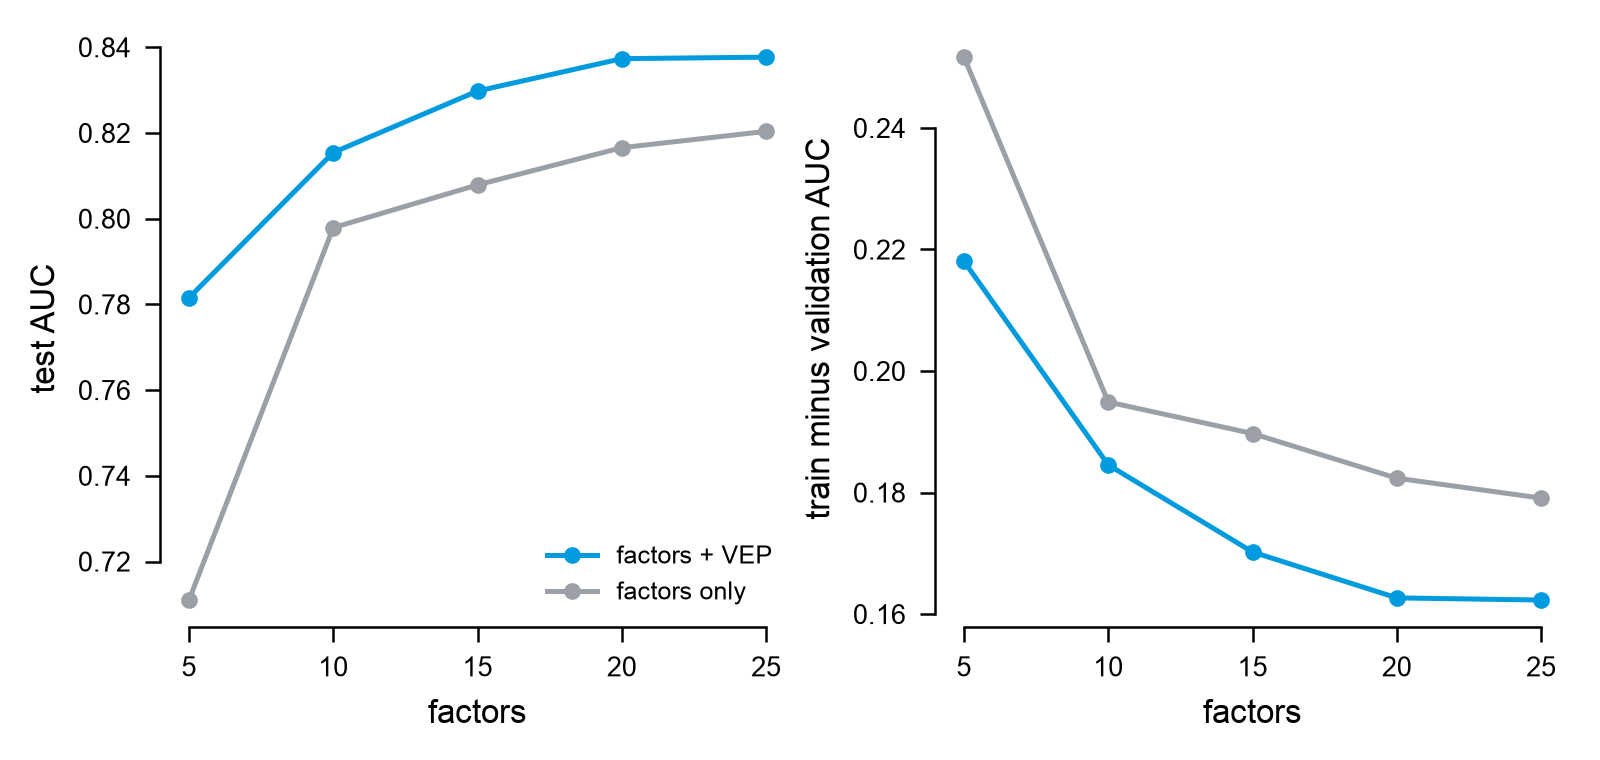

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(5.2, 2.4), sharex=True)
COLOUR = {"factors only": "#9aa0a6", "factors + VEP": "#009ADE"}
for ax, metric in zip(axes, ["test auc", "gap"]):
    for arm, block in summary.reset_index().groupby("arm"):
        ax.plot(block.factors, block[metric], marker="o", ms=3, lw=1.2,
                color=COLOUR[arm], label=arm)
    ax.set_xlabel("factors")
    ax.set_xticks(FACTOR_COUNTS)
    ax.tick_params(labelsize=6.5)
axes[0].set_ylabel("test AUC")
axes[1].set_ylabel("train minus validation AUC")
axes[0].legend(frameon=False, fontsize=6)
fig.tight_layout(pad=0.3)
save_plot(fig, "perturbseq_factors_vs_vep")
plt.show()

In [30]:
rows = []
for metric in ["test auc", "test ap", "test macro f1", "gap"]:
    for count in FACTOR_COUNTS:
        block = results[results.factors == count]
        with_vep = block[block.arm == "factors + VEP"][metric].to_numpy()
        without = block[block.arm == "factors only"][metric].to_numpy()
        difference = with_vep - without
        error = difference.std(ddof=1) / np.sqrt(len(difference))
        rows.append({
            "metric": metric, "factors": count, "difference": difference.mean(),
            "paired se": error, "|t|": abs(difference.mean() / error),
            "positive": f"{int((difference > 0).sum())}/{len(difference)}",
        })
pd.DataFrame(rows).set_index(["metric", "factors"])

difference  paired se        |t| positive
metric        factors                                           
test auc      5          0.070538   0.003525  20.010932    30/30
              10         0.017538   0.002544   6.893123    29/30
              15         0.021905   0.002380   9.205779    29/30
              20         0.020768   0.002037  10.194906    29/30
              25         0.017323   0.002163   8.007979    27/30
test ap       5          0.135106   0.004030  33.524858    30/30
              10         0.049166   0.003174  15.490937    30/30
              15         0.044364   0.003004  14.765998    30/30
              20         0.039216   0.002219  17.672810    30/30
              25         0.034268   0.002220  15.436955    30/30
test macro f1 5          0.078785   0.004071  19.353114    30/30
              10         0.033077   0.004080   8.107265    28/30
              15         0.024511   0.004004   6.121328    28/30
              20         0.020209   0.003636   5.558583    26/30
              25         0.016382   0.003701   4.426655    25/30
gap           5         -0.033594   0.003482   9.648423     1/30
              10        -0.010354   0.002489   4.160258     9/30
              15        -0.019500   0.002369   8.232414     2/30
              20        -0.019700   0.002042   9.647999     1/30
              25        -0.016777   0.002172   7.725299     3/30

In [31]:
GROUPING_FACTORS = 15
inflation = pd.DataFrame([
    {
        "arm": "factors + VEP" if with_vep else "factors only",
        "grouped": run(GROUPING_FACTORS, with_vep)["test auc"].mean(),
        "ungrouped": run(GROUPING_FACTORS, with_vep, grouped=False)["test auc"].mean(),
    }
    for with_vep in (False, True)
]).set_index("arm")
inflation["inflation"] = inflation.ungrouped - inflation.grouped
inflation

,grouped,ungrouped,inflation
arm,,,
factors only,0.807876,0.815142,0.007266
factors + VEP,0.829781,0.984136,0.154355


## Splitting the two resistance categories


In [32]:
SUBTYPES = ["control", "drug addiction", "canonical drug resistance"]
SUBTYPE_INDEX = {name: position for position, name in enumerate(SUBTYPES)}
subtype = usable.variant_class_highest_impact.map(SUBTYPE_INDEX).to_numpy()

MULTICLASS = dict(
    objective="multi:softprob", num_class=3, tree_method="hist", n_estimators=300,
    max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
)
pd.Series(subtype).map({v: k for k, v in SUBTYPE_INDEX.items()}).value_counts().rename(
    "cells"
).to_frame().join(
    usable.groupby("variant_class_highest_impact").attributed.nunique().rename("variants")
)

,cells,variants
control,6656,196
drug addiction,511,12
canonical drug resistance,335,8


In [33]:
def downsample_three(index, generator):
    """Each class cut to the size of the second largest, stratified by gene as in 04."""
    present = pd.Series(subtype[index]).value_counts()
    target = int(present.iloc[1]) if len(present) > 1 else len(index)
    return np.concatenate([
        stratified_sample(index[subtype[index] == position], target, generator)
        for position in range(len(SUBTYPES))
    ])

In [34]:
def run_three(count, with_vep):
    """AUPRC, AUROC and F1 per class, one row per downsample and seed."""
    features = np.hstack([factors[count], vep_matrix]) if with_vep else factors[count]
    rows = []
    for draw, seed in product(range(DRAWS), range(SEEDS)):
        generator = np.random.default_rng(draw)
        index = downsample_three(np.arange(len(subtype)), generator)
        subset, truth, unit = features[index], subtype[index], groups[index]
        probability = np.zeros((len(index), len(SUBTYPES)))
        splitter = StratifiedGroupKFold(FOLDS, shuffle=True, random_state=seed)
        for train, test in splitter.split(subset, truth, unit):
            model = XGBClassifier(random_state=seed, **MULTICLASS)
            model.fit(subset[train], truth[train])
            probability[test] = model.predict_proba(subset[test])
        predicted = probability.argmax(axis=1)
        row = {"factors": count, "arm": "factors + VEP" if with_vep else "factors only"}
        for name, position in SUBTYPE_INDEX.items():
            binary = (truth == position).astype(int)
            # average precision is the area under the precision-recall curve
            row[name] = average_precision_score(binary, probability[:, position])
            row[f"{name} AUROC"] = roc_auc_score(binary, probability[:, position])
            row[f"{name} F1"] = f1_score(binary, (predicted == position).astype(int),
                                         zero_division=0)
        row["macro F1"] = f1_score(truth, predicted, average="macro", zero_division=0)
        rows.append(row)
    return pd.DataFrame(rows)

In [35]:
three_class = pd.concat(
    [run_three(count, with_vep) for count in FACTOR_COUNTS for with_vep in (False, True)],
    ignore_index=True,
)
three_summary = three_class.groupby(["arm", "factors"]).mean(numeric_only=True)
three_summary[SUBTYPES].rename(columns={n: f"{n} AUPRC" for n in SUBTYPES})

control AUPRC  drug addiction AUPRC  \
arm           factors                                        
factors + VEP 5             0.603756              0.913484   
              10            0.650116              0.919062   
              15            0.682624              0.919868   
              20            0.699028              0.922154   
              25            0.711775              0.922296   
factors only  5             0.595305              0.658845   
              10            0.658222              0.747217   
              15            0.652418              0.771867   
              20            0.659725              0.780884   
              25            0.668790              0.785363   

                       canonical drug resistance AUPRC  
arm           factors                                   
factors + VEP 5                               0.442213  
              10                              0.443824  
              15                              0.444381  
              20                              0.459882  
              25                              0.480722  
factors only  5                               0.287246  
              10                              0.307284  
              15                              0.333377  
              20                              0.359730  
              25                              0.347175

In [36]:
three_summary[[f"{name} AUROC" for name in SUBTYPES]]

control AUROC  drug addiction AUROC  \
arm           factors                                        
factors + VEP 5             0.784729              0.907127   
              10            0.823468              0.912848   
              15            0.840212              0.914620   
              20            0.847823              0.917233   
              25            0.852176              0.919062   
factors only  5             0.721751              0.763890   
              10            0.796687              0.819036   
              15            0.805116              0.829856   
              20            0.816422              0.837569   
              25            0.821181              0.840850   

                       canonical drug resistance AUROC  
arm           factors                                   
factors + VEP 5                               0.692739  
              10                              0.720996  
              15                              0.740625  
              20                              0.755319  
              25                              0.767887  
factors only  5                               0.570577  
              10                              0.595504  
              15                              0.619397  
              20                              0.639639  
              25                              0.627365

In [37]:
three_summary[[f"{name} F1" for name in SUBTYPES] + ["macro F1"]]

control F1  drug addiction F1  \
arm           factors                                  
factors + VEP 5          0.703850           0.840710   
              10         0.733272           0.850465   
              15         0.737802           0.849918   
              20         0.740164           0.850668   
              25         0.740041           0.851888   
factors only  5          0.583978           0.626305   
              10         0.666409           0.695058   
              15         0.680078           0.717669   
              20         0.693752           0.728226   
              25         0.699607           0.726861   

                       canonical drug resistance F1  macro F1  
arm           factors                                          
factors + VEP 5                            0.254522  0.599694  
              10                           0.256747  0.613495  
              15                           0.261300  0.616340  
              20                           0.257697  0.616176  
              25                           0.265951  0.619293  
factors only  5                            0.231123  0.480468  
              10                           0.244194  0.535220  
              15                           0.284108  0.560618  
              20                           0.321541  0.581173  
              25                           0.301973  0.576147

In [38]:
balanced = downsample_three(np.arange(len(subtype)), np.random.default_rng(0))
pd.DataFrame({
    "cells": [int((subtype[balanced] == p).sum()) for p in SUBTYPE_INDEX.values()],
    "prevalence": [float((subtype[balanced] == p).mean()) for p in SUBTYPE_INDEX.values()],
}, index=SUBTYPES)

,cells,prevalence
control,512,0.377025
drug addiction,511,0.376289
canonical drug resistance,335,0.246686


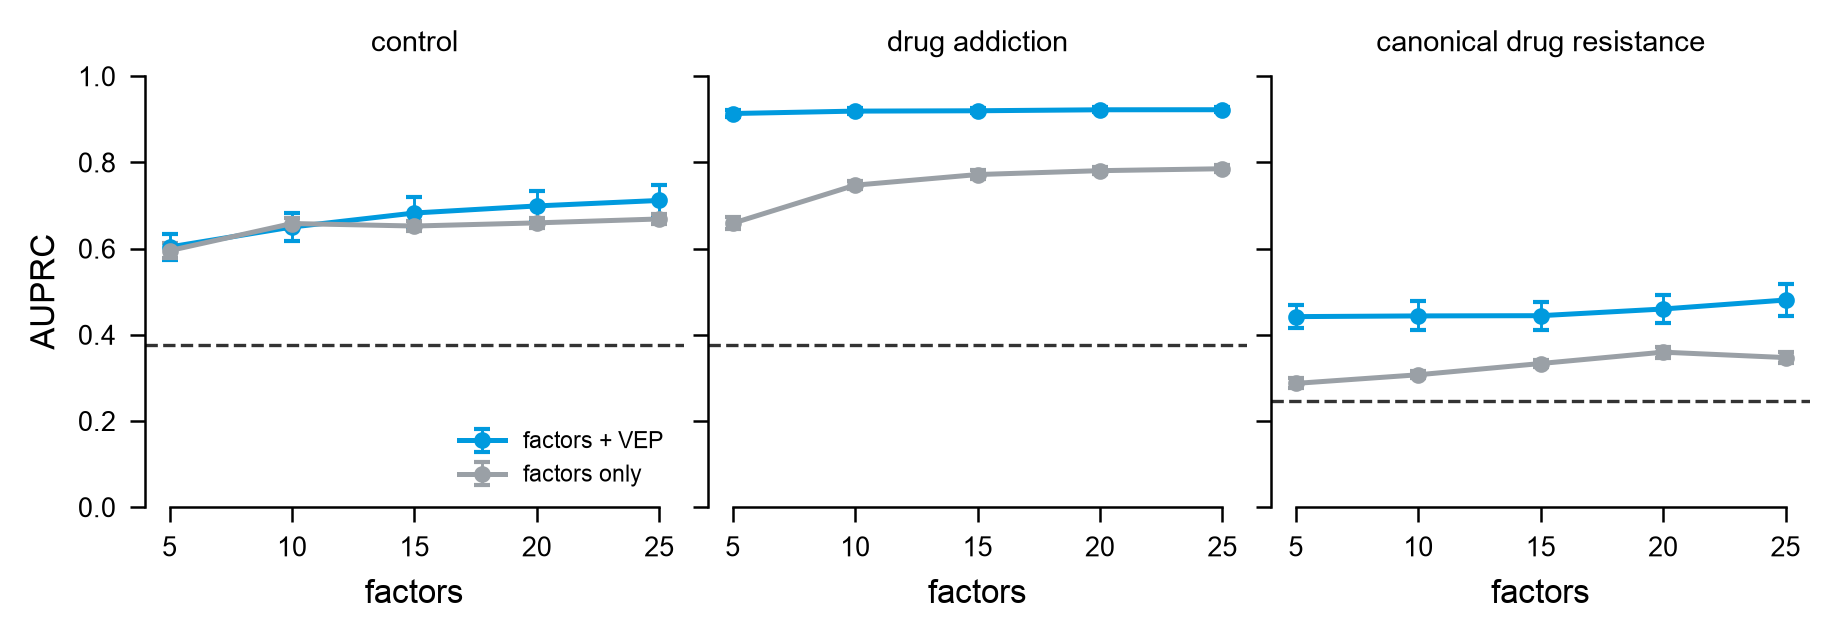

In [47]:
spread = three_class.groupby(["arm", "factors"]).std(numeric_only=True)
prevalence = {
    name: float((subtype[balanced] == position).mean())
    for name, position in SUBTYPE_INDEX.items()
}

fig, axes = plt.subplots(1, 3, figsize=(6, 2), sharex=True, sharey=True)
for ax, name in zip(axes, SUBTYPES):
    for arm, block in three_summary.reset_index().groupby("arm"):
        ax.errorbar(
            block.factors, block[name], yerr=spread.loc[arm, name].to_numpy(),
            marker="o", ms=3, lw=1.2, color=COLOUR[arm], label=arm,
            capsize=2, elinewidth=0.7,
        )
    # the floor a constant predictor reaches is the class prevalence
    ax.axhline(prevalence[name], color="#333333", lw=0.8, ls="--")
    ax.set_title(name, fontsize=7)
    ax.set_xlabel("factors")
    ax.set_xticks(FACTOR_COUNTS)
    ax.set_ylim(0, 1)
    ax.tick_params(labelsize=6.5)
axes[0].set_ylabel("AUPRC")
axes[0].legend(frameon=False, fontsize=5.5, loc="lower right")
fig.tight_layout(pad=0.3)
save_plot(fig, "perturbseq_three_class")  # error bars: s.d. over the repeats
plt.show()